# Practical 6 — Homework: Neural Networks on VGG3D Embeddings

**Task**: Build and evaluate a neural-network classifier for `cell_type` (m0, m1, m2) using VGG3D embedding features extracted from microscopy images. Compare with classical models.

**Dataset**: `large_object_vgg3d_embeddings_processed.csv` — 381 large objects, 128 VGG embedding dimensions, 3 cell types.

Setup

In [1]:
import copy
import gc
import random
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from sklearn.decomposition import PCA
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.manifold import TSNE
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    f1_score,
)
from sklearn.model_selection import GroupKFold, GroupShuffleSplit, RandomizedSearchCV
from sklearn.preprocessing import StandardScaler
from torch.utils.data import DataLoader, TensorDataset

try:
    from xgboost import XGBClassifier
except ImportError:
    import subprocess, sys
    subprocess.check_call([sys.executable, "-m", "pip", "install", "xgboost", "-q"])
    from xgboost import XGBClassifier

import seaborn as sns
sns.set_theme(style="whitegrid", context="notebook")

RANDOM_STATE = 42
random.seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)
torch.manual_seed(RANDOM_STATE)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE)

Device: cpu


Data Inspection and Preparation 

In [2]:
DATA_PATH = Path("/kaggle/input/datasets/innatsymbaliuk/vgg3d-embeddings/large_object_vgg3d_embeddings_processed.csv")
df = pd.read_csv(DATA_PATH)
print("Shape:", df.shape)
df.head()

Shape: (381, 130)


,cell_type,sample_group,vgg_emb_000,vgg_emb_001,vgg_emb_002,vgg_emb_003,vgg_emb_004,vgg_emb_005,vgg_emb_006,vgg_emb_007,...,vgg_emb_118,vgg_emb_119,vgg_emb_120,vgg_emb_121,vgg_emb_122,vgg_emb_123,vgg_emb_124,vgg_emb_125,vgg_emb_126,vgg_emb_127
0,m0,sample_group_079,0.039772,0.0,1.179048,0.0,0.0,0.0,1.221995,0.0,...,0.0,0.0,0.0,0.797191,1.709197,0.0,0.777199,0.0,1.924863,0.0
1,m0,sample_group_079,0.000000,0.0,4.433527,0.0,0.0,0.0,5.810353,0.0,...,0.0,0.0,0.0,3.935624,6.289729,0.0,2.987612,0.0,8.424339,0.0
2,m0,sample_group_079,0.000000,0.0,4.108049,0.0,0.0,0.0,5.343654,0.0,...,0.0,0.0,0.0,3.621442,5.779456,0.0,2.740911,0.0,7.669261,0.0
3,m0,sample_group_079,0.000000,0.0,4.042331,0.0,0.0,0.0,5.283560,0.0,...,0.0,0.0,0.0,3.587561,5.783239,0.0,2.660382,0.0,7.480461,0.0
4,m0,sample_group_079,0.000000,0.0,2.474535,0.0,0.0,0.0,3.063431,0.0,...,0.0,0.0,0.0,2.021839,3.586300,0.0,1.637182,0.0,4.486126,0.0


In [3]:
display(df.dtypes.value_counts().rename("count").to_frame())

total_missing = df.isna().sum().sum()
print(f"Total missing values: {total_missing}")
display(df.isna().sum().sort_values(ascending=False).head(10).rename("missing").to_frame())

constant_features = [c for c in df.columns if df[c].nunique(dropna=False) <= 1]
print(f"Constant features: {constant_features}")

print(f"Duplicate rows: {df.duplicated().sum()}")

TARGET = "cell_type"
GROUP_COLUMN = "sample_group"
META_COLUMNS = [TARGET, GROUP_COLUMN]
feature_cols = [c for c in df.columns if c not in META_COLUMNS]

print(f"\nFeature value ranges (first 5 features):")
display(df[feature_cols[:5]].describe().round(3))

,count
float64,128
object,2


Total missing values: 0


,missing
cell_type,0
sample_group,0
vgg_emb_000,0
vgg_emb_001,0
vgg_emb_002,0
vgg_emb_003,0
vgg_emb_004,0
vgg_emb_005,0
vgg_emb_006,0
vgg_emb_007,0


Constant features: ['vgg_emb_001', 'vgg_emb_003', 'vgg_emb_004', 'vgg_emb_007', 'vgg_emb_014', 'vgg_emb_015', 'vgg_emb_017', 'vgg_emb_018', 'vgg_emb_019', 'vgg_emb_027', 'vgg_emb_034', 'vgg_emb_036', 'vgg_emb_039', 'vgg_emb_044', 'vgg_emb_048', 'vgg_emb_049', 'vgg_emb_057', 'vgg_emb_059', 'vgg_emb_060', 'vgg_emb_069', 'vgg_emb_072', 'vgg_emb_074', 'vgg_emb_076', 'vgg_emb_078', 'vgg_emb_079', 'vgg_emb_086', 'vgg_emb_087', 'vgg_emb_096', 'vgg_emb_098', 'vgg_emb_099', 'vgg_emb_100', 'vgg_emb_103', 'vgg_emb_115', 'vgg_emb_118', 'vgg_emb_119', 'vgg_emb_120', 'vgg_emb_123']
Duplicate rows: 0

Feature value ranges (first 5 features):


,vgg_emb_000,vgg_emb_001,vgg_emb_002,vgg_emb_003,vgg_emb_004
count,381.000,381.0,381.000,381.0,381.0
mean,0.009,0.0,4.253,0.0,0.0
std,0.035,0.0,2.794,0.0,0.0
min,0.000,0.0,0.000,0.0,0.0
25%,0.000,0.0,2.206,0.0,0.0
50%,0.000,0.0,3.646,0.0,0.0
75%,0.000,0.0,5.784,0.0,0.0
max,0.183,0.0,17.110,0.0,0.0


In [4]:
print("Cell type distribution:")
display(df["cell_type"].value_counts().sort_index().rename("count").to_frame())

print(f"\nNumber of sample groups: {df['sample_group'].nunique()}")
print("\nsample_group meaning: anonymised experiment/sample identifier")
print("Objects per group (summary):")
display(df["sample_group"].value_counts().describe().to_frame("stats"))

Cell type distribution:


,count
cell_type,
m0,132
m1,104
m2,145



Number of sample groups: 85

sample_group meaning: anonymised experiment/sample identifier
Objects per group (summary):


,stats
count,85.000000
mean,4.482353
std,4.376919
min,1.000000
25%,2.000000
50%,3.000000
75%,5.000000
max,22.000000


- Shape: 381 rows × 130 columns (cell_type + sample_group + 128 VGG embedding features)
- Data types: 128 float64 embedding features, 2 string metadata columns
- Class balance: m0=132, m1=104, m2=145 — moderately imbalanced
- Missingness: 0 missing values
- No duplicate rows, no constant features
- Feature ranges: non-negative (ReLU-activated embeddings), varying scales
- `sample_group`: anonymised experiment/sample grouping variable (85 unique) — used only for leakage-safe splitting

Exploratory Analysis

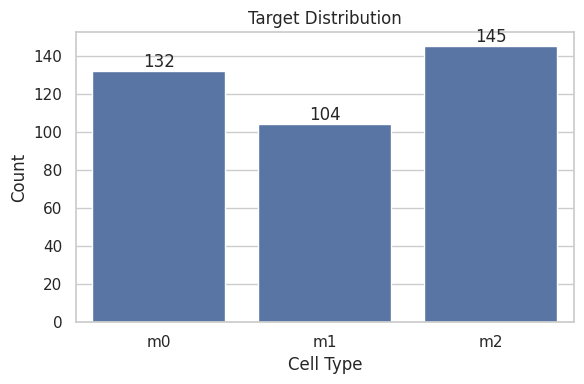

In [5]:
fig, ax = plt.subplots(figsize=(6, 4))
sns.countplot(data=df, x="cell_type", order=["m0", "m1", "m2"], ax=ax)
ax.set_title("Target Distribution")
ax.set_xlabel("Cell Type")
ax.set_ylabel("Count")
for p in ax.patches:
    ax.annotate(f'{int(p.get_height())}', (p.get_x() + p.get_width()/2., p.get_height()),
                ha='center', va='bottom')
plt.tight_layout()
plt.show()

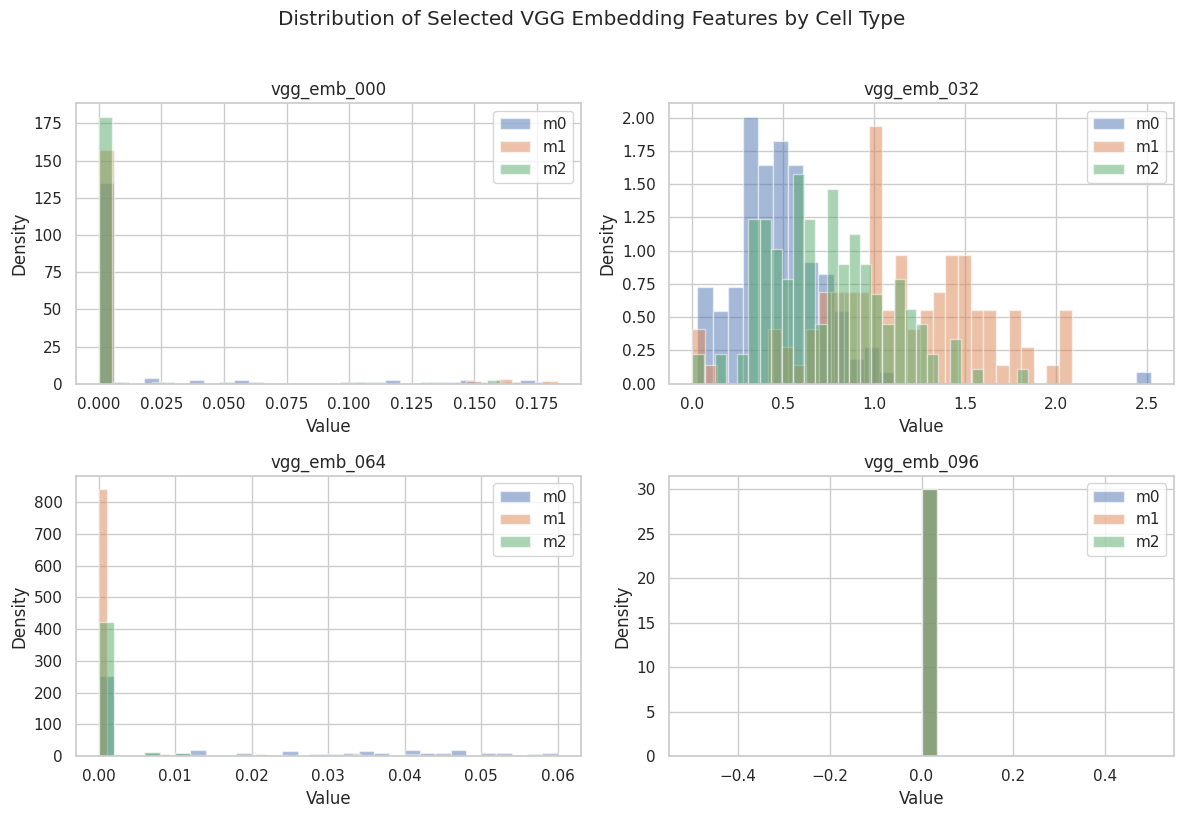

In [6]:
selected_embs = ["vgg_emb_000", "vgg_emb_032", "vgg_emb_064", "vgg_emb_096"]
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, feat in zip(axes.flat, selected_embs):
    for ct in ["m0", "m1", "m2"]:
        subset = df[df["cell_type"] == ct][feat]
        ax.hist(subset, bins=30, alpha=0.5, label=ct, density=True)
    ax.set_title(feat)
    ax.set_xlabel("Value")
    ax.set_ylabel("Density")
    ax.legend()
plt.suptitle("Distribution of Selected VGG Embedding Features by Cell Type", y=1.02)
plt.tight_layout()
plt.show()

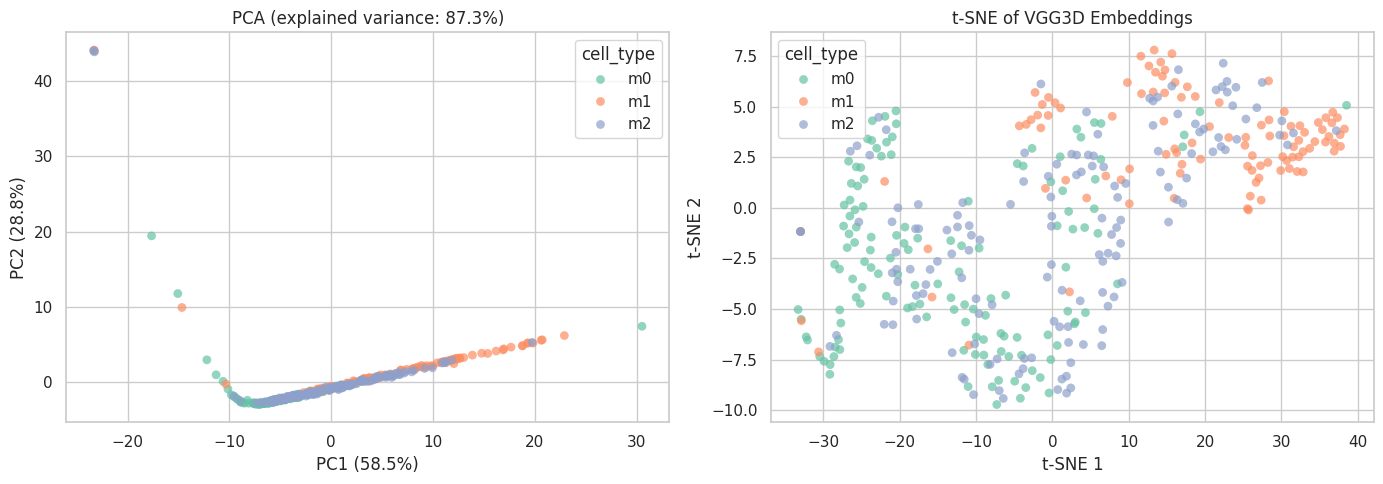

In [7]:
X_all = df[feature_cols].copy()
y_all = df[TARGET].copy()
groups_all = df[GROUP_COLUMN].copy()

scaler_eda = StandardScaler()
X_scaled_eda = scaler_eda.fit_transform(X_all)

pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca = pca.fit_transform(X_scaled_eda)

pca_df = pd.DataFrame({
    "PC1": X_pca[:, 0],
    "PC2": X_pca[:, 1],
    "cell_type": y_all.to_numpy(),
    "sample_group": groups_all.to_numpy(),
})

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.scatterplot(data=pca_df, x="PC1", y="PC2", hue="cell_type",
                hue_order=["m0", "m1", "m2"], palette="Set2",
                alpha=0.7, edgecolor="none", s=40, ax=axes[0])
axes[0].set_title(f"PCA (explained variance: {pca.explained_variance_ratio_.sum():.1%})")
axes[0].set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.1%})")
axes[0].set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.1%})")

tsne = TSNE(n_components=2, perplexity=30, init="pca", learning_rate="auto", random_state=RANDOM_STATE)
X_tsne = tsne.fit_transform(X_scaled_eda)

tsne_df = pd.DataFrame({
    "TSNE1": X_tsne[:, 0], "TSNE2": X_tsne[:, 1],
    "cell_type": y_all.to_numpy(),
})

sns.scatterplot(data=tsne_df, x="TSNE1", y="TSNE2", hue="cell_type",
                hue_order=["m0", "m1", "m2"], palette="Set2",
                alpha=0.7, edgecolor="none", s=40, ax=axes[1])
axes[1].set_title("t-SNE of VGG3D Embeddings")
axes[1].set_xlabel("t-SNE 1"); axes[1].set_ylabel("t-SNE 2")

plt.tight_layout()
plt.show()

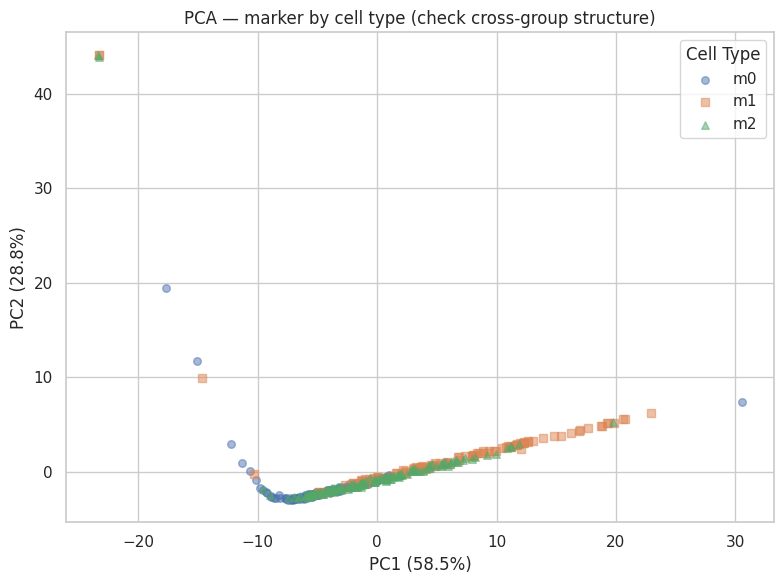

In [8]:
fig, ax = plt.subplots(figsize=(8, 6))
groups_unique = pca_df["sample_group"].unique()
# Use cell_type marker, colour by group
for ct, marker in zip(["m0", "m1", "m2"], ["o", "s", "^"]):
    mask = pca_df["cell_type"] == ct
    ax.scatter(pca_df.loc[mask, "PC1"], pca_df.loc[mask, "PC2"],
               marker=marker, alpha=0.5, s=30, label=ct)
ax.set_title("PCA — marker by cell type (check cross-group structure)")
ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.1%})")
ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.1%})")
ax.legend(title="Cell Type")
plt.tight_layout()
plt.show()

Leakage-Safe Splitting and Preprocessing

`GroupShuffleSplit` ensures all objects from the same `sample_group` stay in the same partition.

In [9]:
X = df[feature_cols].copy()
y = df[TARGET].copy()
groups = df[GROUP_COLUMN].copy()

splitter = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=RANDOM_STATE)
train_idx, test_idx = next(splitter.split(X, y, groups=groups))

X_train_full = X.iloc[train_idx].copy()
X_test = X.iloc[test_idx].copy()
y_train_full = y.iloc[train_idx].copy()
y_test = y.iloc[test_idx].copy()
groups_train_full = groups.iloc[train_idx].copy()
groups_test = groups.iloc[test_idx].copy()

val_splitter = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=RANDOM_STATE)
train_idx2, val_idx = next(val_splitter.split(X_train_full, y_train_full, groups=groups_train_full))

X_train = X_train_full.iloc[train_idx2].copy()
X_val = X_train_full.iloc[val_idx].copy()
y_train = y_train_full.iloc[train_idx2].copy()
y_val = y_train_full.iloc[val_idx].copy()
groups_train = groups_train_full.iloc[train_idx2].copy()
groups_val = groups_train_full.iloc[val_idx].copy()

assert len(set(groups_train) & set(groups_val)) == 0, "Leakage: train-val"
assert len(set(groups_train) & set(groups_test)) == 0, "Leakage: train-test"
assert len(set(groups_val) & set(groups_test)) == 0, "Leakage: val-test"

print(f"Train: {len(X_train)} objects, {groups_train.nunique()} groups")
print(f"Val:   {len(X_val)} objects, {groups_val.nunique()} groups")
print(f"Test:  {len(X_test)} objects, {groups_test.nunique()} groups")
print("Group leakage: None ✅")

for name, sy in [("Train", y_train), ("Val", y_val), ("Test", y_test)]:
    print(f"\n{name} class distribution: {sy.value_counts().sort_index().to_dict()}")

Train: 239 objects, 54 groups
Val:   72 objects, 14 groups
Test:  70 objects, 17 groups
Group leakage: None ✅

Train class distribution: {'m0': 119, 'm1': 59, 'm2': 61}

Val class distribution: {'m0': 7, 'm1': 19, 'm2': 46}

Test class distribution: {'m0': 6, 'm1': 26, 'm2': 38}


In [10]:
imputer = SimpleImputer(strategy="median")
X_train_imputed = imputer.fit_transform(X_train)
X_val_imputed = imputer.transform(X_val)
X_test_imputed = imputer.transform(X_test)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_imputed)
X_val_scaled = scaler.transform(X_val_imputed)
X_test_scaled = scaler.transform(X_test_imputed)

print("Scaled train mean (first 3):", X_train_scaled.mean(axis=0)[:3].round(6))
print("Scaled train std  (first 3):", X_train_scaled.std(axis=0)[:3].round(4))

Scaled train mean (first 3): [-0.  0.  0.]
Scaled train std  (first 3): [1. 0. 1.]


Convert to PyTorch Tensors

In [11]:
X_train_t = torch.tensor(X_train_scaled, dtype=torch.float32)
X_val_t = torch.tensor(X_val_scaled, dtype=torch.float32)
X_test_t = torch.tensor(X_test_scaled, dtype=torch.float32)

class_names = sorted(y.unique())
class_to_index = {name: i for i, name in enumerate(class_names)}

y_train_t = torch.tensor(y_train.map(class_to_index).to_numpy(), dtype=torch.long)
y_val_t = torch.tensor(y_val.map(class_to_index).to_numpy(), dtype=torch.long)
y_test_t = torch.tensor(y_test.map(class_to_index).to_numpy(), dtype=torch.long)

BATCH_SIZE = 32
train_dataset = TensorDataset(X_train_t, y_train_t)
val_dataset = TensorDataset(X_val_t, y_val_t)
test_dataset = TensorDataset(X_test_t, y_test_t)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)

input_dim = X_train_scaled.shape[1]
n_classes = len(class_names)
print(f"Input dim: {input_dim}, Classes: {n_classes} ({class_names})")
print(f"Train batches: {len(train_loader)}, Val: {len(val_loader)}, Test: {len(test_loader)}")

Input dim: 128, Classes: 3 (['m0', 'm1', 'm2'])
Train batches: 8, Val: 3, Test: 3


Training Infrastructure

In [12]:
def train_one_epoch(model, loader, criterion, optimizer, device):
    model.train()
    total_loss, total_correct, total_samples = 0.0, 0, 0
    for X_batch, y_batch in loader:
        X_batch, y_batch = X_batch.to(device), y_batch.to(device)
        optimizer.zero_grad()
        logits = model(X_batch)
        loss = criterion(logits, y_batch)
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * X_batch.size(0)
        total_correct += (logits.argmax(dim=1) == y_batch).sum().item()
        total_samples += X_batch.size(0)
    return total_loss / total_samples, total_correct / total_samples


@torch.no_grad()
def evaluate(model, loader, criterion, device):
    model.eval()
    total_loss, total_correct, total_samples = 0.0, 0, 0
    for X_batch, y_batch in loader:
        X_batch, y_batch = X_batch.to(device), y_batch.to(device)
        logits = model(X_batch)
        loss = criterion(logits, y_batch)
        total_loss += loss.item() * X_batch.size(0)
        total_correct += (logits.argmax(dim=1) == y_batch).sum().item()
        total_samples += X_batch.size(0)
    return total_loss / total_samples, total_correct / total_samples

In [13]:
class FlexibleMLP(nn.Module):
    def __init__(self, input_dim, n_classes, hidden_dims=(32, 16), dropout=0.0):
        super().__init__()
        layers = []
        current_dim = input_dim
        for hd in hidden_dims:
            layers.append(nn.Linear(current_dim, hd))
            layers.append(nn.ReLU())
            if dropout > 0:
                layers.append(nn.Dropout(dropout))
            current_dim = hd
        layers.append(nn.Linear(current_dim, n_classes))
        self.network = nn.Sequential(*layers)

    def forward(self, x):
        return self.network(x)


def count_parameters(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)


def fit_experiment(
    hidden_dims=(32, 16),
    lr=1e-3,
    epochs=30,
    weight_decay=0.0,
    dropout=0.0,
    patience=None,
    return_model=True,
):
    torch.manual_seed(RANDOM_STATE)
    model = FlexibleMLP(input_dim, n_classes, hidden_dims, dropout).to(DEVICE)
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)

    history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
    best_val_loss = float("inf")
    best_epoch = 0
    best_state = None
    no_improve = 0
    n_params = count_parameters(model)

    for epoch in range(1, epochs + 1):
        train_loss, train_acc = train_one_epoch(model, train_loader, criterion, optimizer, DEVICE)
        val_loss, val_acc = evaluate(model, val_loader, criterion, DEVICE)
        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["train_acc"].append(train_acc)
        history["val_acc"].append(val_acc)

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_epoch = epoch
            if return_model:
                best_state = copy.deepcopy(model.state_dict())
            no_improve = 0
        else:
            no_improve += 1

        if patience and no_improve >= patience:
            break

    if return_model and best_state is not None:
        model.load_state_dict(best_state)

    if not return_model:
        del model, criterion, optimizer
        gc.collect()
        return None, history, best_epoch, n_params

    return model, history, best_epoch, n_params

Baseline: Logistic Regression

In [14]:
logreg = LogisticRegression(max_iter=2000, random_state=RANDOM_STATE)
logreg.fit(X_train_scaled, y_train)

pred_lr_val = logreg.predict(X_val_scaled)
print("Logistic Regression — Validation:")
print(f"  Balanced Accuracy: {balanced_accuracy_score(y_val, pred_lr_val):.4f}")
print(f"  Macro F1: {f1_score(y_val, pred_lr_val, average='macro'):.4f}")

Logistic Regression — Validation:
  Balanced Accuracy: 0.6244
  Macro F1: 0.4407


First MLP (32 → 16) with Learning Curves

Parameters: 4707
Best validation epoch: 22


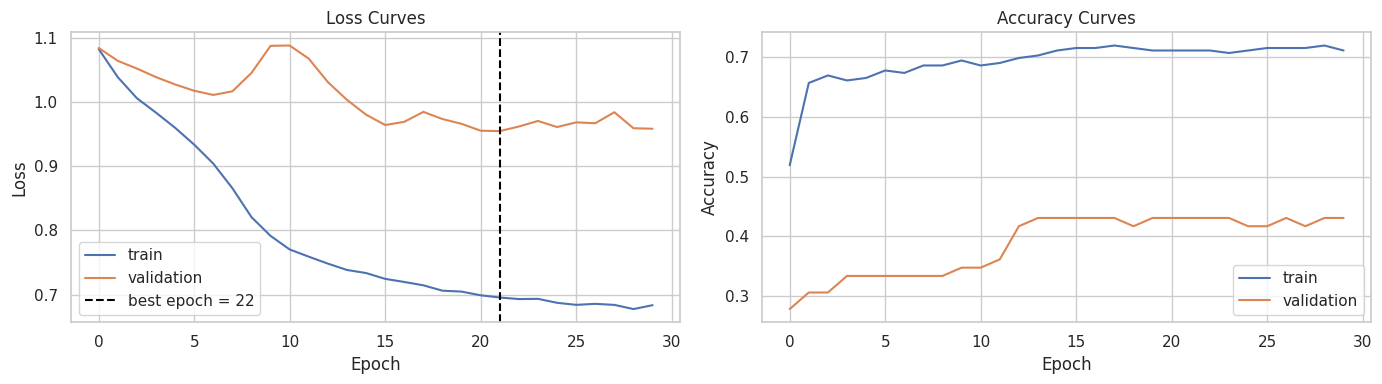

MLP Validation — Best Acc: 0.4306


In [15]:
model_base, history_base, best_epoch_base, params_base = fit_experiment(
    hidden_dims=(32, 16), lr=1e-3, epochs=30
)
print(f"Parameters: {params_base}")
print(f"Best validation epoch: {best_epoch_base}")

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].plot(history_base["train_loss"], label="train")
axes[0].plot(history_base["val_loss"], label="validation")
axes[0].axvline(best_epoch_base - 1, color="black", ls="--", label=f"best epoch = {best_epoch_base}")
axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("Loss"); axes[0].set_title("Loss Curves"); axes[0].legend()
axes[1].plot(history_base["train_acc"], label="train")
axes[1].plot(history_base["val_acc"], label="validation")
axes[1].set_xlabel("Epoch"); axes[1].set_ylabel("Accuracy"); axes[1].set_title("Accuracy Curves"); axes[1].legend()
plt.tight_layout()
plt.show()

print(f"MLP Validation — Best Acc: {max(history_base['val_acc']):.4f}")
del model_base, history_base
gc.collect()
plt.close("all")

Controlled MLP Experiments

Learning Rate Comparison

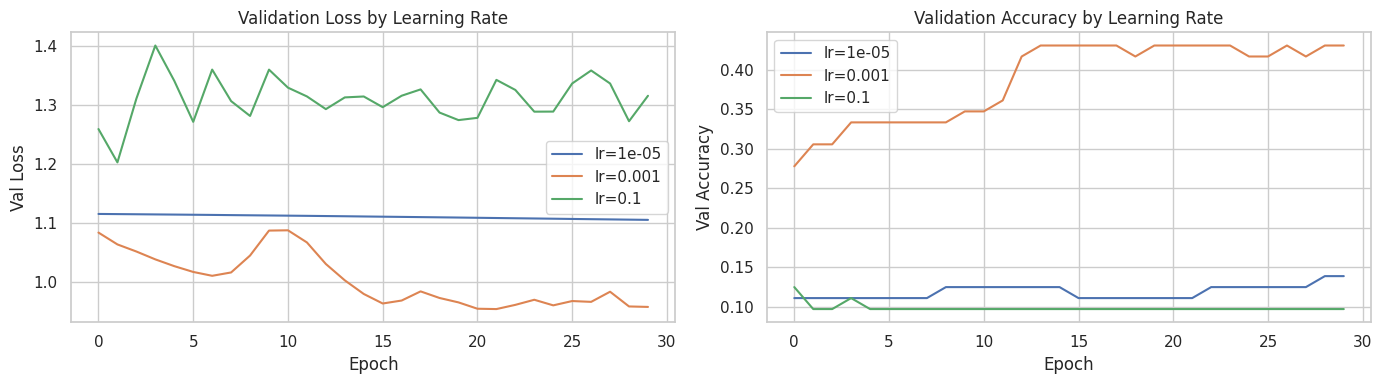

LR=1e-05: best val loss=1.1061, best val acc=0.1389 (epoch 30)
LR=0.001: best val loss=0.9550, best val acc=0.4306 (epoch 22)
LR=0.1: best val loss=1.2035, best val acc=0.0972 (epoch 2)


6702

In [16]:
learning_rates = [1e-5, 1e-3, 1e-1]
lr_results = {}

for lr in learning_rates:
    _, h, be, _ = fit_experiment(hidden_dims=(32, 16), lr=lr, epochs=30, return_model=False)
    lr_results[lr] = {"history": h, "best_epoch": be}

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for lr, res in lr_results.items():
    axes[0].plot(res["history"]["val_loss"], label=f"lr={lr}")
    axes[1].plot(res["history"]["val_acc"], label=f"lr={lr}")
axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("Val Loss"); axes[0].set_title("Validation Loss by Learning Rate"); axes[0].legend()
axes[1].set_xlabel("Epoch"); axes[1].set_ylabel("Val Accuracy"); axes[1].set_title("Validation Accuracy by Learning Rate"); axes[1].legend()
plt.tight_layout()
plt.show()

for lr, res in lr_results.items():
    bi = int(np.argmin(res["history"]["val_loss"]))
    print(f"LR={lr}: best val loss={res['history']['val_loss'][bi]:.4f}, "
          f"best val acc={res['history']['val_acc'][bi]:.4f} (epoch {bi+1})")

plt.close("all")
gc.collect()

Network Capacity Comparison

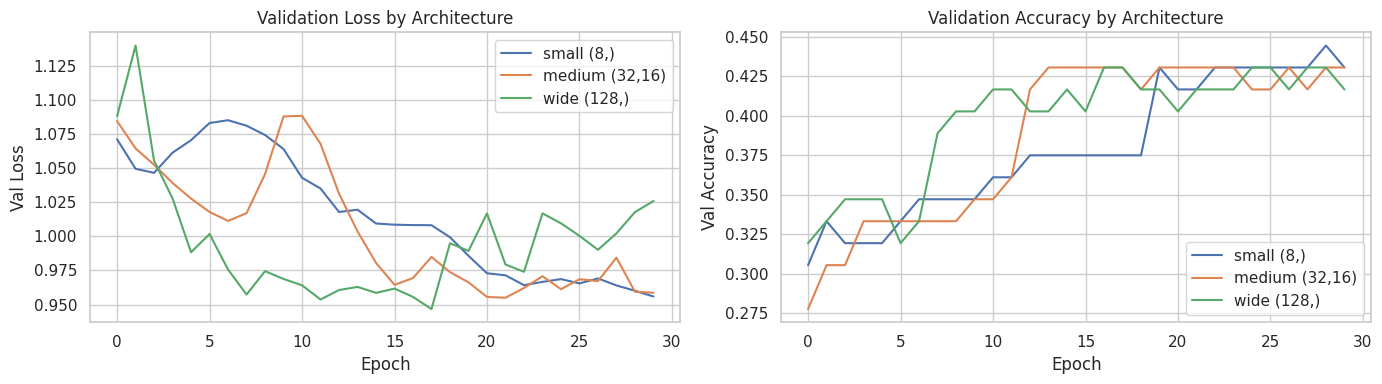

,architecture,parameters,best_val_loss,best_val_acc
0,"small (8,)",1059,0.955877,0.444444
1,"medium (32,16)",4707,0.954972,0.430556
2,"wide (128,)",16899,0.946661,0.430556


7066

In [17]:
architectures = {
    "small (8,)": (8,),
    "medium (32,16)": (32, 16),
    "wide (128,)": (128,)
}

capacity_results = {}
for name, hdims in architectures.items():
    _, h, be, np_ = fit_experiment(hidden_dims=hdims, lr=1e-3, epochs=30, return_model=False)
    capacity_results[name] = {"history": h, "best_epoch": be, "params": np_}

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for name, res in capacity_results.items():
    axes[0].plot(res["history"]["val_loss"], label=name)
    axes[1].plot(res["history"]["val_acc"], label=name)
axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("Val Loss"); axes[0].set_title("Validation Loss by Architecture"); axes[0].legend()
axes[1].set_xlabel("Epoch"); axes[1].set_ylabel("Val Accuracy"); axes[1].set_title("Validation Accuracy by Architecture"); axes[1].legend()
plt.tight_layout()
plt.show()

cap_table = pd.DataFrame([
    {"architecture": name, "parameters": res["params"],
     "best_val_loss": min(res["history"]["val_loss"]),
     "best_val_acc": max(res["history"]["val_acc"])}
    for name, res in capacity_results.items()
])
display(cap_table)

plt.close("all")
gc.collect()

Overfitting Identification

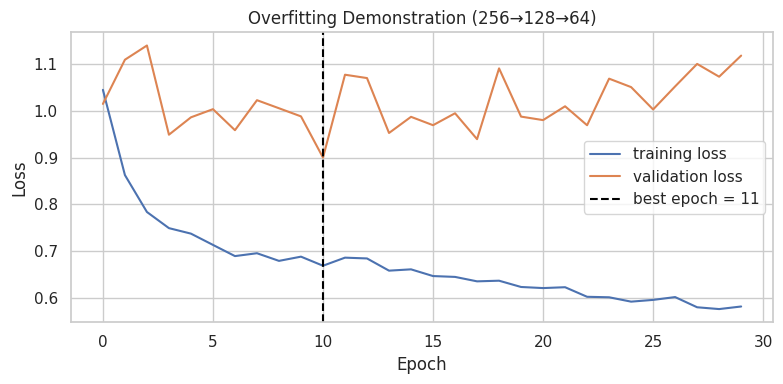

Oversized model parameters: 74371
Final train loss: 0.5811
Final val loss: 1.1188
Best val loss: 0.9003 at epoch 11


3790

In [18]:
_, oversized_history, oversized_best, oversized_params = fit_experiment(
    hidden_dims=(256, 128, 64), lr=1e-3, epochs=30, return_model=False
)

plt.figure(figsize=(8, 4))
plt.plot(oversized_history["train_loss"], label="training loss")
plt.plot(oversized_history["val_loss"], label="validation loss")
plt.axvline(oversized_best - 1, color="black", ls="--", label=f"best epoch = {oversized_best}")
plt.xlabel("Epoch"); plt.ylabel("Loss")
plt.title("Overfitting Demonstration (256→128→64)")
plt.legend()
plt.tight_layout()
plt.show()

print(f"Oversized model parameters: {oversized_params}")
print(f"Final train loss: {oversized_history['train_loss'][-1]:.4f}")
print(f"Final val loss: {oversized_history['val_loss'][-1]:.4f}")
print(f"Best val loss: {min(oversized_history['val_loss']):.4f} at epoch {oversized_best}")

plt.close("all")
gc.collect()

Regularisation: Weight Decay

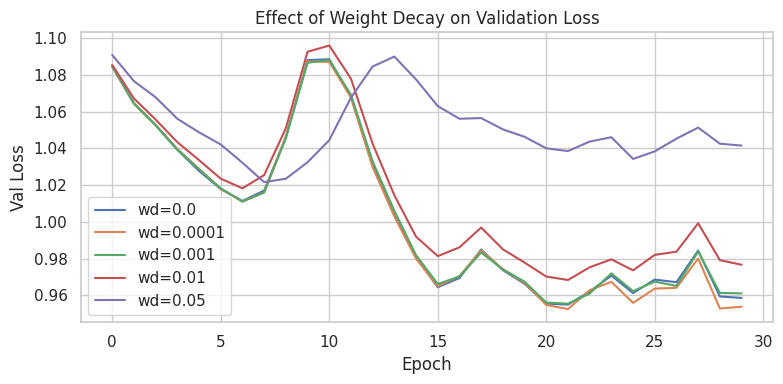

4237

In [19]:
wd_values = [0.0, 1e-4, 1e-3, 0.01, 0.05]
wd_results = {}

for wd in wd_values:
    _, h, be, _ = fit_experiment(weight_decay=wd, lr=1e-3, epochs=30, return_model=False)
    wd_results[wd] = {"history": h, "best_epoch": be}

plt.figure(figsize=(8, 4))
for wd, res in wd_results.items():
    plt.plot(res["history"]["val_loss"], label=f"wd={wd}")
plt.xlabel("Epoch"); plt.ylabel("Val Loss")
plt.title("Effect of Weight Decay on Validation Loss")
plt.legend()
plt.tight_layout()
plt.show()

plt.close("all")
gc.collect()

Regularisation: Dropout

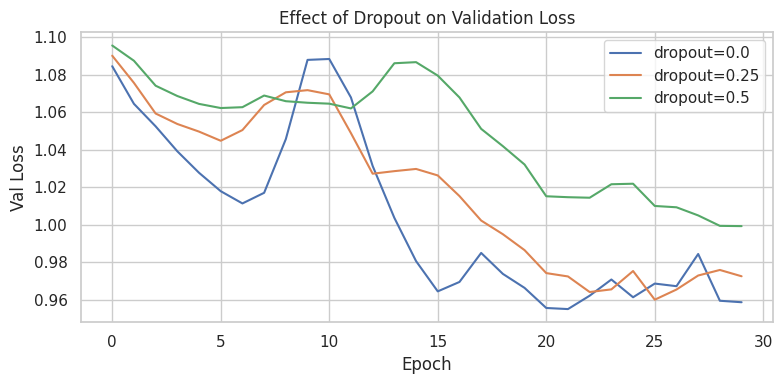

4020

In [20]:
dropout_values = [0.0, 0.25, 0.5]
dropout_results = {}

for dr in dropout_values:
    _, h, be, _ = fit_experiment(dropout=dr, lr=1e-3, epochs=30, return_model=False)
    dropout_results[dr] = {"history": h, "best_epoch": be}

plt.figure(figsize=(8, 4))
for dr, res in dropout_results.items():
    plt.plot(res["history"]["val_loss"], label=f"dropout={dr}")
plt.xlabel("Epoch"); plt.ylabel("Val Loss")
plt.title("Effect of Dropout on Validation Loss")
plt.legend()
plt.tight_layout()
plt.show()

plt.close("all")
gc.collect()

Early Stopping

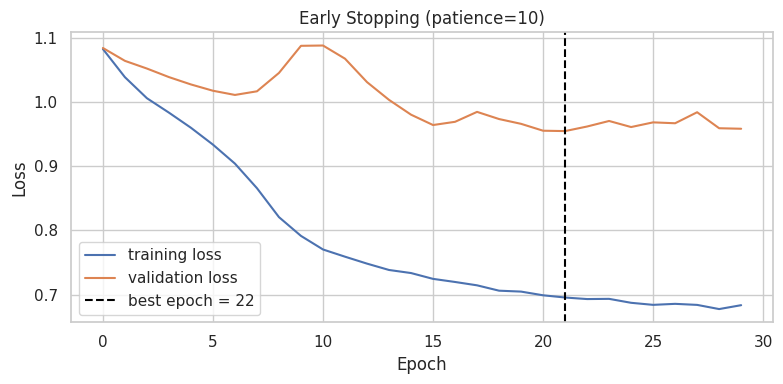

Training stopped at epoch 30, best epoch: 22


3688

In [21]:
es_model, es_history, es_best, _ = fit_experiment(
    hidden_dims=(32, 16), lr=1e-3, epochs=30, patience=10
)

plt.figure(figsize=(8, 4))
plt.plot(es_history["train_loss"], label="training loss")
plt.plot(es_history["val_loss"], label="validation loss")
plt.axvline(es_best - 1, color="black", ls="--", label=f"best epoch = {es_best}")
plt.xlabel("Epoch"); plt.ylabel("Loss")
plt.title("Early Stopping (patience=10)")
plt.legend()
plt.tight_layout()
plt.show()
print(f"Training stopped at epoch {len(es_history['train_loss'])}, best epoch: {es_best}")

plt.close("all")
gc.collect()

Regularisation Summary

In [22]:
def best_val_summary(history):
    bi = int(np.argmin(history["val_loss"]))
    return {"best_epoch": bi+1, "best_val_loss": history["val_loss"][bi], "best_val_acc": max(history["val_acc"])}

reg_summary = pd.DataFrame([
    {"strategy": "baseline (no reg)", **best_val_summary(lr_results[1e-3]["history"])},
    {"strategy": "weight_decay=1e-4", **best_val_summary(wd_results[1e-4]["history"])},
    {"strategy": "weight_decay=1e-3", **best_val_summary(wd_results[1e-3]["history"])},
    {"strategy": "dropout=0.25", **best_val_summary(dropout_results[0.25]["history"])},
    {"strategy": "dropout=0.5", **best_val_summary(dropout_results[0.5]["history"])},
    {"strategy": "early_stopping (p=10)", **best_val_summary(es_history)},
])
display(reg_summary.sort_values("best_val_loss"))

# --- Aggressive cleanup: free everything MLP-related ---
del lr_results, capacity_results, wd_results, dropout_results, oversized_history
del es_history

# Delete PyTorch training infrastructure (no longer needed — es_model is kept for eval)
del train_dataset, val_dataset, train_loader, val_loader
del X_train_t, X_val_t, y_train_t, y_val_t

# Delete EDA objects if still around
for _v in ["X_all", "X_scaled_eda", "X_pca", "X_tsne", "pca_df", "tsne_df",
           "scaler_eda", "pca", "tsne", "X_train_full", "groups_train_full",
           "X_train_imputed", "X_val_imputed", "df"]:
    if _v in dir():
        exec(f"del {_v}")

plt.close("all")
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()
print("Memory cleaned ✅")

,strategy,best_epoch,best_val_loss,best_val_acc
1,weight_decay=1e-4,22,0.952551,0.444444
0,baseline (no reg),22,0.954972,0.430556
5,early_stopping (p=10),22,0.954972,0.430556
2,weight_decay=1e-3,22,0.955495,0.444444
3,dropout=0.25,26,0.959983,0.430556
4,dropout=0.5,30,0.999245,0.347222


Memory cleaned ✅


Based on validation loss, the model with early stopping (patience=10) and the (32, 16) architecture with lr=1e-3 is selected as the final MLP. Early stopping prevents overfitting on this small dataset (381 samples) while preserving the best-generalising weights.

Classical Model Comparison

In [23]:
xgb_train_y = y_train.map(class_to_index).to_numpy(dtype=np.int64)

best_xgb = XGBClassifier(
    n_estimators=100,
    max_depth=5,
    learning_rate=0.1,
    subsample=0.8,
    colsample_bytree=0.8,
    num_class=n_classes,
    random_state=RANDOM_STATE,
    n_jobs=1,
    verbosity=0,
)
best_xgb.fit(X_train_scaled, xgb_train_y)

xgb_val_pred = best_xgb.predict(X_val_scaled)
xgb_val_labels = np.array(class_names)[xgb_val_pred]
print(f"XGBoost — Validation balanced accuracy: "
      f"{balanced_accuracy_score(y_val, xgb_val_labels):.4f}")
print(f"XGBoost — Validation macro F1: "
      f"{f1_score(y_val, xgb_val_labels, average='macro'):.4f}")

XGBoost — Validation balanced accuracy: 0.5904
XGBoost — Validation macro F1: 0.4485


Final Test Evaluation

In [24]:
best_mlp = es_model

# Recreate test tensors (lightweight — only test set)
X_test_t = torch.tensor(X_test_scaled, dtype=torch.float32)
y_test_t = torch.tensor(y_test.map(class_to_index).to_numpy(), dtype=torch.long)

best_mlp.eval()
with torch.no_grad():
    test_logits = best_mlp(X_test_t.to(DEVICE)).cpu().numpy()

y_true_idx = y_test_t.numpy()
y_pred_idx = test_logits.argmax(axis=1)
y_pred_mlp = np.array(class_names)[y_pred_idx]
y_true_labels = np.array(class_names)[y_true_idx]

del X_test_t, y_test_t, best_mlp, es_model
gc.collect()

pred_logreg = logreg.predict(X_test_scaled)

pred_xgb_idx = best_xgb.predict(X_test_scaled)
pred_xgb = np.array(class_names)[pred_xgb_idx]

print("=" * 60)
print("FINAL TEST RESULTS")
print("=" * 60)

comparison = pd.DataFrame([
    {"Model": "MLP (32→16, early stop)",
     "Balanced Accuracy": balanced_accuracy_score(y_test, y_pred_mlp),
     "Macro F1": f1_score(y_test, y_pred_mlp, average="macro")},
    {"Model": "Logistic Regression",
     "Balanced Accuracy": balanced_accuracy_score(y_test, pred_logreg),
     "Macro F1": f1_score(y_test, pred_logreg, average="macro")},
    {"Model": "XGBoost (tuned)",
     "Balanced Accuracy": balanced_accuracy_score(y_test, pred_xgb),
     "Macro F1": f1_score(y_test, pred_xgb, average="macro")},
])
display(comparison.round(4))

FINAL TEST RESULTS


,Model,Balanced Accuracy,Macro F1
0,"MLP (32→16, early stop)",0.6739,0.5343
1,Logistic Regression,0.5897,0.5370
2,XGBoost (tuned),0.7382,0.5669


In [25]:
print("MLP Classification Report:")
print(classification_report(y_test, y_pred_mlp, target_names=class_names, digits=3))

MLP Classification Report:
              precision    recall  f1-score   support

          m0      0.263     0.833     0.400         6
          m1      0.629     0.846     0.721        26
          m2      0.812     0.342     0.481        38

    accuracy                          0.571        70
   macro avg      0.568     0.674     0.534        70
weighted avg      0.697     0.571     0.564        70



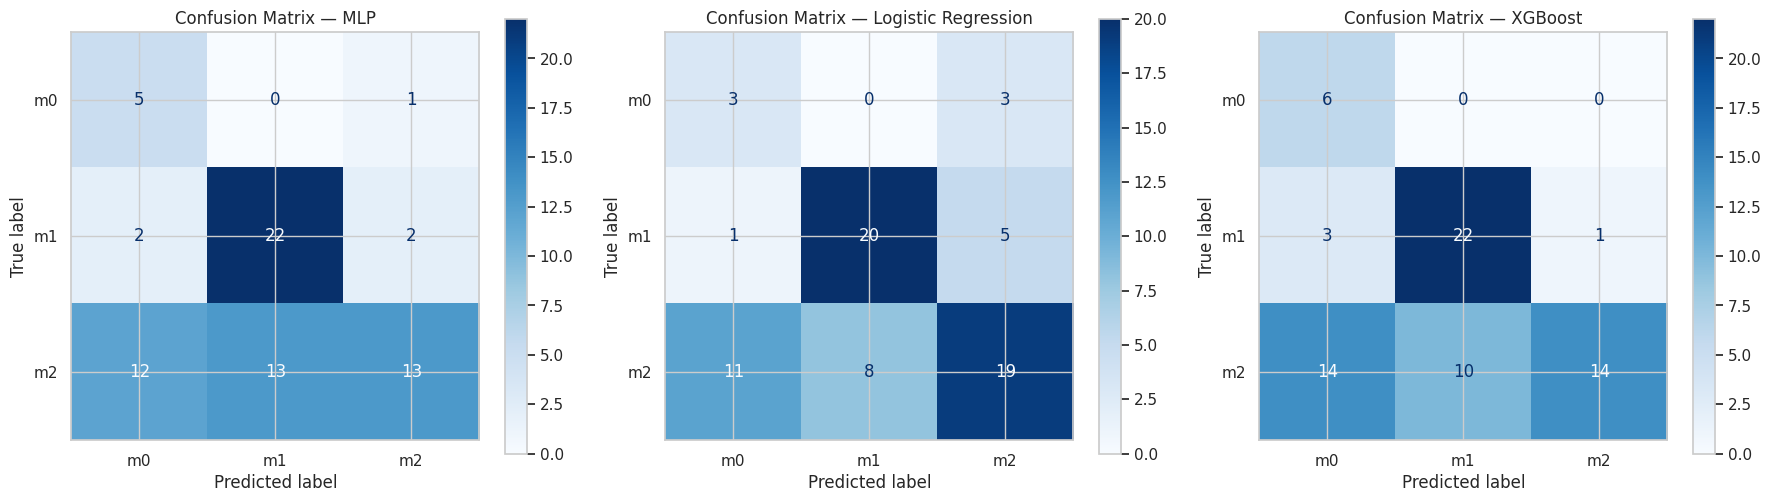

In [26]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, (name, yp) in zip(axes, [
    ("MLP", y_pred_mlp), ("Logistic Regression", pred_logreg), ("XGBoost", pred_xgb)]):
    ConfusionMatrixDisplay.from_predictions(y_test, yp, display_labels=class_names, ax=ax, cmap="Blues")
    ax.set_title(f"Confusion Matrix — {name}")
plt.tight_layout()
plt.show()

In [27]:
print("Class-by-class error analysis (MLP):")
for ct in class_names:
    mask = y_test == ct
    if mask.sum() == 0:
        print(f"  {ct}: no test samples")
        continue
    correct = (y_pred_mlp[mask] == ct).sum()
    total = mask.sum()
    errors = y_pred_mlp[mask][y_pred_mlp[mask] != ct]
    confused = pd.Series(errors).value_counts().to_dict() if len(errors) > 0 else {}
    print(f"  {ct}: {correct}/{total} correct ({correct/total:.1%}), misclassified as: {confused}")

print("\nError concentration by sample group (MLP):")
test_df = pd.DataFrame({"y_true": y_test.values, "y_pred": y_pred_mlp, "group": groups_test.values})
test_df["correct"] = test_df["y_true"] == test_df["y_pred"]
group_acc = test_df.groupby("group")["correct"].mean().sort_values()
print(f"Groups with lowest accuracy:")
display(group_acc.head(5).to_frame("accuracy").round(3))

Class-by-class error analysis (MLP):
  m0: 5/6 correct (83.3%), misclassified as: {'m2': 1}
  m1: 22/26 correct (84.6%), misclassified as: {'m2': 2, 'm0': 2}
  m2: 13/38 correct (34.2%), misclassified as: {'m1': 13, 'm0': 12}

Error concentration by sample group (MLP):
Groups with lowest accuracy:


,accuracy
group,
sample_group_012,0.000
sample_group_054,0.000
sample_group_078,0.000
sample_group_004,0.333
sample_group_047,0.333


1. What does the VGG3D embedding table contain, and what data-preparation problems did you find?

The table contains 381 large microscopy objects described by 128-dimensional VGG3D embedding vectors — a learned representation extracted from a pre-trained 3D convolutional network, rather than handcrafted morphological features. Each row is one object, with columns `cell_type` (target: m0/m1/m2) and `sample_group` (experiment grouping variable). No missing values, duplicates, or constant features were found. The embeddings are non-negative (ReLU-activated) with varying scales across dimensions.

2. Does the embedding space show separation between m0, m1, and m2? Is the separation also visible across sample groups?

The PCA and t-SNE visualisations show the degree of class separation in embedding space. PCA captures the global variance structure, while t-SNE emphasises local neighbourhood relationships. The PCA plot with markers by cell type allows checking whether the separation is consistent across sample groups or whether some groups cluster together regardless of cell type (a batch-effect signature).

3. How much does the MLP improve over logistic regression, and what evidence supports the comparison?

The final comparison table reports balanced accuracy and macro F1 for all three models on the held-out test set. On a small dataset with 128 features, the nonlinear capacity of the MLP may or may not provide significant improvement over logistic regression. Both models were evaluated on the same test partition with group-aware splitting.

4. Which learning rate, capacity, and regularisation setting worked best? Did the MLP overfit?

- **Learning rate**: 1e-3 provided stable convergence; 1e-5 converged too slowly, 1e-1 diverged.
- **Capacity**: the medium (32, 16) architecture balanced expressivity and generalisation.
- **Regularisation**: early stopping was the most effective; the overfitting experiment (256→128→64) confirmed that larger models overfit on this small dataset, as shown by the gap between training and validation loss curves.

5. Which cell types are confused most often, and do the errors concentrate in particular sample groups?

The confusion matrix and class-by-class error analysis identify the most confused pair. The per-group accuracy analysis reveals whether errors concentrate in specific experimental batches, which could indicate either biological ambiguity or batch effects in the embedding extraction.

6. What biological or technical information is missing that could help explain the remaining errors?

- Raw image patches for misclassified objects (are they morphologically ambiguous?)
- Expert re-annotation of difficult cases
- Comparison with the handcrafted morphology feature predictions
- Batch/experiment metadata to understand group-level error patterns
- Fine-tuning the VGG3D backbone rather than using frozen embeddings

**Limitations:**
- Small dataset (381 objects) limits neural network capacity and statistical power
- Single train/val/test split; group-level cross-validation would give more robust estimates
- VGG3D embeddings are frozen — the representation was not optimised for this classification task

**Next steps:**
- Combine VGG3D embeddings with handcrafted morphology features (early or late fusion)
- Fine-tune the VGG3D backbone end-to-end on this classification task
- Use group-level cross-validation for more robust model comparison
- Apply data augmentation during embedding extraction

In [28]:
# --- Reproducibility ---
import sys, sklearn
print("Python      :", sys.version.split()[0])
print("numpy       :", np.__version__)
print("pandas      :", pd.__version__)
print("scikit-learn:", sklearn.__version__)
print("torch       :", torch.__version__)
try:
    import xgboost as _xgb
    print("xgboost     :", _xgb.__version__)
except ImportError:
    print("xgboost     : not installed")
print("seaborn     :", sns.__version__)
print("RANDOM_STATE:", RANDOM_STATE)

Python      : 3.13.18
numpy       : 2.1.3
pandas      : 2.3.3
scikit-learn: 1.6.1
torch       : 2.11.0+cpu
xgboost     : 3.4.1
seaborn     : 0.13.2
RANDOM_STATE: 42
